Celula 1 - importuri si path-ul catre date

In [3]:

import json
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_DIR = Path("../Data")


Celula 2 - 

În fișierele originale, un document poate conține versiuni în mai multe limbi. Noi extragem doar textul în română și etichetele de nivel 1.  Etichetele „de nivel 1” se referă la cel mai general nivel de categorii din sistemul de clasificare al Uniunii Europene (numit EUROVOC), care este organizat ca un arbore ierarhic (de la general la foarte specific).

• Nivelul 1 (Domenii principale — 21 de categorii mari): Sunt marile teme generale, exact ca secțiunile unui ziar. De exemplu: Politică, Finanțe, Agricultură, Mediu, Transport, Energie.

In [4]:

def load_romanian_documents(file_path):
    documents = []

    with open(file_path, "r", encoding="utf-8") as file:
        for line in file:
            document = json.loads(line)

            text = document["text"].get("ro")

            if not text:
                continue

            documents.append({
                "celex_id": document["celex_id"],
                "text": text,
                "labels": document["eurovoc_concepts"]["level_1"]
            })

    return pd.DataFrame(documents)


def find_split_file(filename):
    matches = list(DATA_DIR.rglob(filename))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Ma asteptam la un singur {filename}, "
            f"dar am gasit {len(matches)}."
        )

    return matches[0]


train_df = load_romanian_documents(
    find_split_file("train.jsonl")
)

val_df = load_romanian_documents(
    find_split_file("dev.jsonl")
)

test_df = load_romanian_documents(
    find_split_file("test.jsonl")
)

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Test:", len(test_df))


Training: 15921
Validation: 5000
Test: 5000


Celula 3 - 

Vreau sa vad cum arata primul document; 
cum este reprezentat efectiv un document legislativ și ce categorii i-au fost atribuite.

In [5]:

document = train_df.iloc[0]

print("ID:", document["celex_id"])
print("\nTEXT:")
print(document["text"][:1000])
print("\nLABELS:")
print(document["labels"])

ID: 32006D0213

TEXT:
32006D0213
L 079/27
JURNALUL OFÍCIAL AL UNIUNII EUROPENE
DECIZIA COMISIEI
din 6 martie 2006
de stabilire a clasificării caracteristicilor de comportare la foc pentru anumite produse de construcții în ceea ce privește pardoselile din lemn și lambriurile și placările din lemn masiv
[notificată cu numărul C(2006) 655]
(Text cu relevanță pentru SEE)
(2006/213/CE)
COMISIA COMUNITĂȚILOR EUROPENE,
având în vedere Tratatul de instituire a Comunității Europene,
având în vedere Directiva 89/106/CEE din 21 decembrie 1988 privind apropierea actelor cu putere de lege și a actelor administrative ale statelor membre referitoare la produsele pentru construcții (1), în special articolul 20 alineatul (2),
întrucât:
(1)
Directiva 89/106/CEE prevede că, pentru a se ține cont de diferitele niveluri de protecție pentru lucrările de construcții în plan național, regional sau local, în documentele de fundamentare este necesar să se definească clasele de performanță ale produselor pentru 

Celula 4 - 

Vreau sa vad primele statistici descriptive

Cât de lung este un document tipic?


Care este cel mai scurt și cel mai lung document?


Câte categorii are în medie un document?


Sunt toate cele 21 de categorii reprezentate?

In [6]:

train_df["word_count"] = train_df["text"].apply(
    lambda text: len(text.split())
)

train_df["label_count"] = train_df["labels"].apply(len)

print(
    train_df[["word_count", "label_count"]].describe()
)

print("\nNumarul de documente:", len(train_df))
print(
    "Numarul de categorii distincte:",
    len(set(label for labels in train_df["labels"] for label in labels))
)

print(
    "Documente fara etichete:",
    (train_df["label_count"] == 0).sum()
)

          word_count   label_count
count   15921.000000  15921.000000
mean     1444.792350      3.434144
std      3220.568777      1.082733
min        96.000000      1.000000
25%       332.000000      3.000000
50%       521.000000      3.000000
75%      1130.000000      4.000000
max    130631.000000     10.000000

Numarul de documente: 15921
Numarul de categorii distincte: 21
Documente fara etichete: 0


Celula 5 - 

Distribuția etichetelor: Graficul ne va arăta dacă avem clase echilibrate sau dacă unele categorii apar mult mai frecvent decât altele.

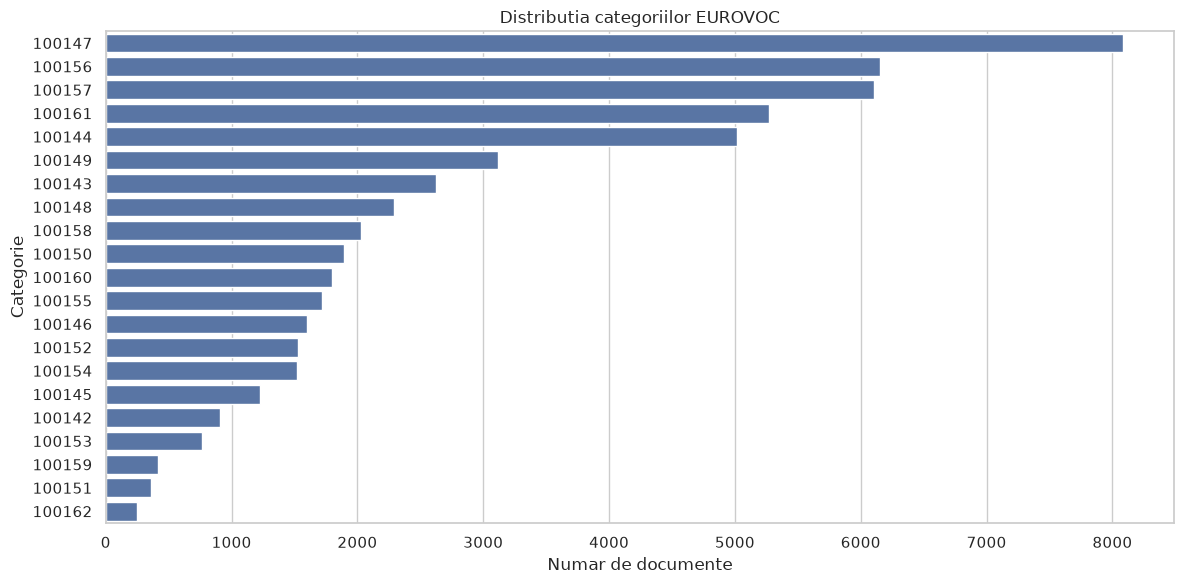

In [7]:

label_counts = Counter(
    label
    for labels in train_df["labels"]
    for label in labels
)

label_df = pd.DataFrame(
    label_counts.items(),
    columns=["Label", "Count"]
).sort_values("Count", ascending=False)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=label_df,
    x="Count",
    y="Label"
)

plt.title("Distributia categoriilor EUROVOC")
plt.xlabel("Numar de documente")
plt.ylabel("Categorie")
plt.tight_layout()

plt.show()

Celula 6 -

Transformarea codurilor EUROVOC în denumiri

Autorii MultiEURLEX pun la dispoziție un fișier eurovoc_descriptors.json, cu denumirile conceptelor asociate identificatorilor.

In [ ]:

import urllib.request
import json

url = (
    "https://raw.githubusercontent.com/nlpaueb/"
    "multi-eurlex/master/data/eurovoc_descriptors.json"
)

descriptor_path = DATA_DIR / "eurovoc_descriptors.json"

if not descriptor_path.exists():
    urllib.request.urlretrieve(url, descriptor_path)

with open(descriptor_path, "r", encoding="utf-8") as f:
    descriptors = json.load(f)


label_df["Category"] = label_df["Label"].map(
    lambda label: descriptors.get(str(label), {}).get("ro", str(label))
)

print(label_df[["Label", "Category", "Count"]].to_string(index=False))


 Label                               Category  Count
100147                                 comerţ   8085
100156   agricultură, silvicultură şi pescuit   6154
100157                 produse agroalimentare   6103
100161                              geografie   5269
100144                      UNIUNEA EUROPEANĂ   5020
100149                       probleme sociale   3121
100143                 relaţii internaţionale   2626
100148                                finanţe   2293
100158     producţie, tehnologie şi cercetare   2032
100150     educaţie comunicare şi comunicaţii   1891
100160                              industrie   1801
100155                     mediu înconjurător   1721
100146                               economie   1596
100152                  afaceri şi concurenţă   1525
100154                              transport   1516
100145                                  drept   1224
100142                               politică    910
100153 angajare în muncă şi condiţii de muncă 

Celula 7 - 

Acum refac graficul, acesta va putea fi inclus direct în prezentarea PowerPoint:

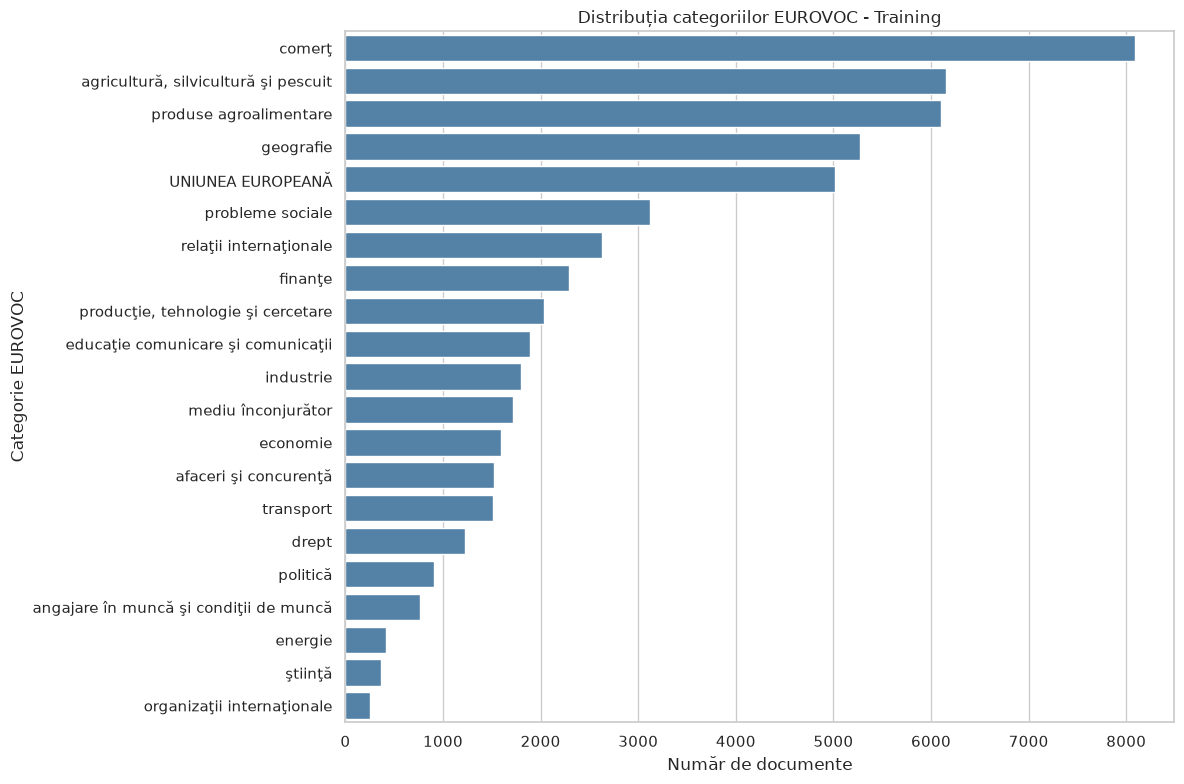

In [13]:

plt.figure(figsize=(12, 8))

sns.barplot(
    data=label_df,
    x="Count",
    y="Category",
    color="steelblue"
)

plt.title("Distribuția categoriilor EUROVOC - Training")
plt.xlabel("Număr de documente")
plt.ylabel("Categorie EUROVOC")

plt.tight_layout()

plt.savefig(
    "../Results/eurovoc_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


Celula 8 - 

Analiza lungimii documentelor

Am limitat axa X la percentila 99 doar pentru a vedea mai clar distribuția. Documentele foarte lungi nu sunt eliminate din dataset.

Ce vrem să descoperim? Dacă majoritatea documentelor depășesc lungimea acceptată de encoder, va trebui să folosim trunchiere, fragmentare (chunking) sau o strategie de selecție a secțiunilor relevante.

count     15921.000000
mean       1444.792350
std        3220.568777
min          96.000000
25%         332.000000
50%         521.000000
75%        1130.000000
90%        3177.000000
95%        5832.000000
99%       15455.200000
max      130631.000000
Name: word_count, dtype: float64


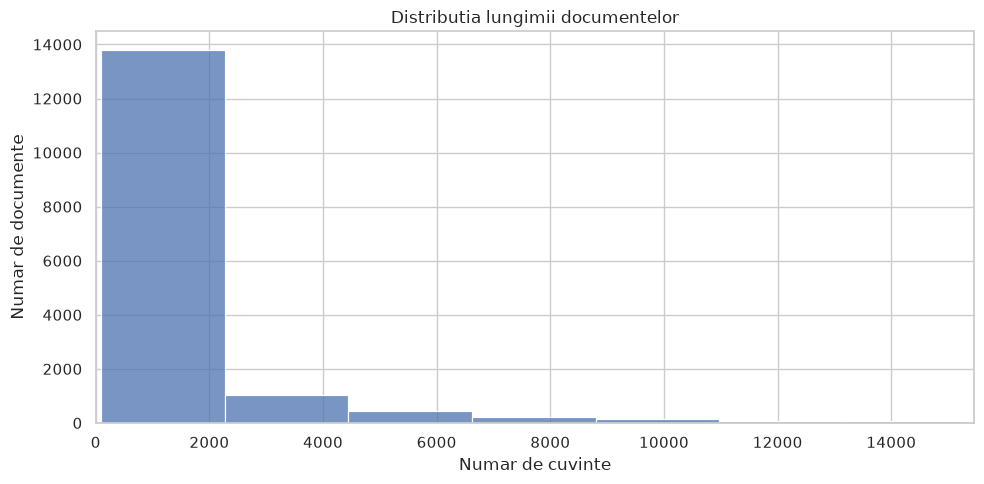

In [14]:

print(train_df["word_count"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

plt.figure(figsize=(10, 5))

sns.histplot(
    train_df["word_count"],
    bins=60
)

plt.title("Distributia lungimii documentelor")
plt.xlabel("Numar de cuvinte")
plt.ylabel("Numar de documente")

plt.xlim(0, train_df["word_count"].quantile(0.99))
plt.tight_layout()
plt.show()


Celula 9 - 

Câte etichete are fiecare document?

label_count
1      198
2     2894
3     5711
4     4693
5     1893
6      420
7       99
8       12
10       1
Name: count, dtype: int64


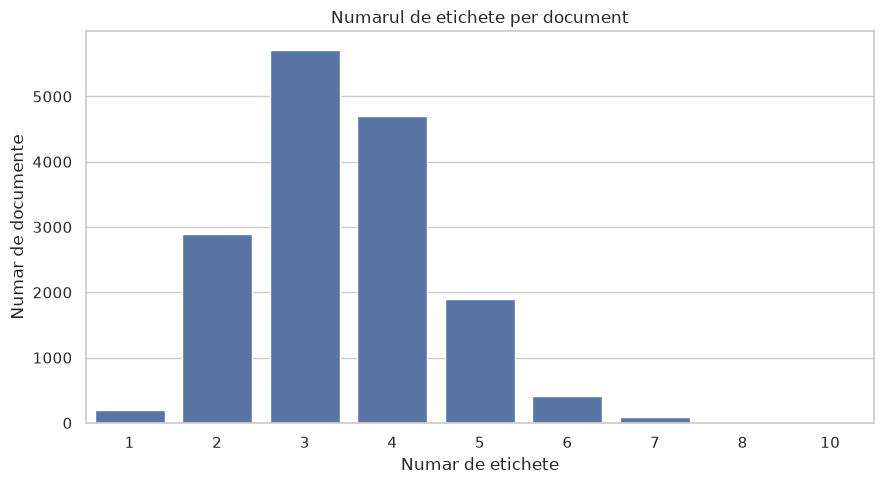

In [15]:

label_count_dist = (
    train_df["label_count"]
    .value_counts()
    .sort_index()
)

print(label_count_dist)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=label_count_dist.index,
    y=label_count_dist.values
)

plt.title("Numarul de etichete per document")
plt.xlabel("Numar de etichete")
plt.ylabel("Numar de documente")
plt.tight_layout()
plt.show()


Celula 10 - 

Verificarea calității datelor

Dacă un document apare în train și în test, evaluarea ar putea deveni înșelătoare: modelul ar fi putut vedea deja acel document la antrenare.

Deocamdată doar verificăm datele, fără să ștergem sau să modificăm exemple.

In [16]:

for name, df in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(f"\n{name}")
    print("Documente:", len(df))
    print("Valori lipsa:")
    print(df.isnull().sum())
    print("ID-uri duplicate:", df["celex_id"].duplicated().sum())
    print("Texte duplicate:", df["text"].duplicated().sum())
    print(
        "Texte goale:",
        df["text"].str.strip().eq("").sum()
    )

train_ids = set(train_df["celex_id"])
val_ids = set(val_df["celex_id"])
test_ids = set(test_df["celex_id"])

print("\nSuprapunere train/validation:", len(train_ids & val_ids))
print("Suprapunere train/test:", len(train_ids & test_ids))
print("Suprapunere validation/test:", len(val_ids & test_ids))



Training
Documente: 15921
Valori lipsa:
celex_id       0
text           0
labels         0
word_count     0
label_count    0
dtype: int64
ID-uri duplicate: 0
Texte duplicate: 1
Texte goale: 0

Validation
Documente: 5000
Valori lipsa:
celex_id    0
text        0
labels      0
dtype: int64
ID-uri duplicate: 0
Texte duplicate: 0
Texte goale: 0

Test
Documente: 5000
Valori lipsa:
celex_id    0
text        0
labels      0
dtype: int64
ID-uri duplicate: 0
Texte duplicate: 0
Texte goale: 0

Suprapunere train/validation: 0
Suprapunere train/test: 0
Suprapunere validation/test: 0


Celula 10.1 -

Am descoperit un singur text duplicat în training. Atenție: duplicated().sum() == 1 înseamnă o apariție suplimentară, nu neapărat un singur document implicat.

Nu îl șterg automat. Verific mai întâi identificatorii și etichetele documentelor.

Pot exista două acte legislative cu identificatori diferiți, dar cu text identic. Dacă și etichetele coincid, poate fi vorba despre o redundanță care merită eliminată din setul de antrenare. Dacă etichetele diferă, avem o problemă mai interesantă: același text este asociat cu răspunsuri diferite.

Nu știm încă în care dintre aceste situații ne aflăm.

In [17]:
duplicates = train_df[
    train_df.duplicated(subset=["text"], keep=False)
].copy()

print("Documente implicate:", len(duplicates))

for _, row in duplicates.iterrows():
    print("\n" + "=" * 60)
    print("CELEX ID:", row["celex_id"])
    print("Etichete:", row["labels"])
    print("Lungime:", row["word_count"], "cuvinte")
    print("Text:", row["text"][:500])

if len(duplicates) == 2:
    labels_1 = set(duplicates.iloc[0]["labels"])
    labels_2 = set(duplicates.iloc[1]["labels"])

    print("\nEtichete identice:", labels_1 == labels_2)


Documente implicate: 2

CELEX ID: 32007D0511
Etichete: ['100145', '100143', '100147', '100161', '100144']
Lungime: 593 cuvinte
Text: DECIZIA CONSILIULUI
din 15 februarie 2007
privind încheierea, în numele Comunității Europene, a unei înțelegeri între Comunitatea Europeană și Republica Islanda și Regatul Norvegiei cu privire la modalitățile de participare a acestor state la Agenția Europeană pentru Gestionarea Cooperării Operaționale la Frontierele Externe ale statelor membre ale Uniunii Europene
(2007/511/CE)
CONSILIUL UNIUNII EUROPENE,
având în vedere Tratatul de instituire a Comunității Europene, în special articolul 62 pun

CELEX ID: 32007D0512
Etichete: ['100145', '100143', '100147', '100161', '100144']
Lungime: 593 cuvinte
Text: DECIZIA CONSILIULUI
din 15 februarie 2007
privind încheierea, în numele Comunității Europene, a unei înțelegeri între Comunitatea Europeană și Republica Islanda și Regatul Norvegiei cu privire la modalitățile de participare a acestor state la Agenția Europ

Celula 10.2 - Eliminarea duplicatului din copia de training

Vom păstra prima apariție, 32007D0511.


In [18]:
train_clean_df = train_df.drop_duplicates(
    subset=["text"],
    keep="first"
).reset_index(drop=True)

print("Training original:", len(train_df))
print("Training curățat:", len(train_clean_df))

print(
    "Documente eliminate:",
    len(train_df) - len(train_clean_df)
)

Training original: 15921
Training curățat: 15920
Documente eliminate: 1


Celula 11: verificarea textelor identice între training, validation și test(Verificarea suprapunerilor între seturi)

De exemplu, dacă un document apare atât în training, cât și în test, modelul ar putea fi evaluat pe un text pe care l-a văzut deja la antrenare. Acest fenomen se numește data leakage și poate conduce la rezultate artificial de bune.

Folosim algoritmul SHA-256 pentru a calcula o amprentă digitală (hash) a fiecărui text.

Dacă două texte sunt exact identice, vor avea aceeași amprentă. Comparând mulțimile de hash-uri, putem identifica suprapunerile dintre seturi fără să comparăm direct documentele, care pot fi foarte lungi.

Important: acest cod verifică numai texte identice, nu și documente foarte asemănătoare.

In [19]:

import hashlib

def get_text_hashes(df):
    return set(
        hashlib.sha256(
            text.encode("utf-8")
        ).hexdigest()
        for text in df["text"]
    )

train_hashes = get_text_hashes(train_clean_df)
val_hashes = get_text_hashes(val_df)
test_hashes = get_text_hashes(test_df)

print("Texte identice train/validation:",
      len(train_hashes & val_hashes))

print("Texte identice train/test:",
      len(train_hashes & test_hashes))

print("Texte identice validation/test:",
      len(val_hashes & test_hashes))


Texte identice train/validation: 0
Texte identice train/test: 0
Texte identice validation/test: 0


Scopul proiectului este să construim un sistem care primește un document juridic în limba română și identifică automat categoriile din care face parte.


In cerinta ni se cere să realizăm acest lucru folosind trei abordări. Acum ne pregătim pentru Modelul 1: Fine-tuned Encoder.

Propun XLM-RoBERTa Base ca prim candidat pentru encoder.

XLM-RoBERTa este un model de inteligență artificială preantrenat pe texte din multe limbi, inclusiv română.

Asta înseamnă că modelul a învățat deja reprezentări ale limbajului, dar nu a fost antrenat de noi să clasifice documente MultiEURLEX în cele 21 de categorii.
Noi urmează să îl specializăm prin fine-tuning.

Dar înainte să-l antrenăm, trebuie să transformăm textele într-un format pe care modelul îl poate procesa.

Aici intervine tokenizerul.
Ce este tokenizerul și de ce avem nevoie de el?
Un model nu primește direct propoziții ca noi, oamenii. El lucrează cu numere.

Tokenizerul este componenta care transformă textul în unități numite tokenuri, iar apoi în identificatori numerici.

Un lucru important: un token nu este neapărat un cuvânt. Un cuvânt mai lung sau mai rar poate fi împărțit în mai multe tokenuri.

Din rezultatele obtinute mai sus știm că:
- Documentul median are 521 de cuvinte.
- 25% dintre documente au peste 1.130 de cuvinte.
- Cel mai lung document are 130.631 de cuvinte.
Dar XLM-RoBERTa Base poate procesa în mod obișnuit maximum 512 tokenuri într-o singură secvență.

Atenție: nu 512 cuvinte, ci 512 tokenuri!

Să presupunem că un document are 2.000 de tokenuri.

Dacă aplicăm o trunchiere simplă la 512, am elimina 74,4% din tokenurile documentului.


Ce se întâmplă dacă informațiile care ne spun că documentul aparține categoriei „Mediu înconjurător” se află spre final?

Modelul nu le-ar vedea.

De aceea, nu vrem să trunchiem documentele fără să investigăm mai întâi cât text am pierde.

Celula 12 – Încărcarea tokenizerului XLM-RoBERTa

Acum încep analiza tokenizării. Voi folosi tokenizerul modelului propus pentru primul experiment: FacebookAI/xlm-roberta-base.  (Tokenizerul asociat modelului XLM-RoBERTa)

In [21]:
from transformers import AutoTokenizer

MODEL_NAME = "FacebookAI/xlm-roberta-base"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

print("Tokenizer:", tokenizer.__class__.__name__)
print("Limita modelului:", tokenizer.model_max_length)
print(
    "Tokenuri speciale:",
    tokenizer.num_special_tokens_to_add(pair=False)
)

Tokenizer: XLMRobertaTokenizer
Limita modelului: 512
Tokenuri speciale: 2


2 = Numărul de tokenuri speciale adăugate unui text

Așadar, într-o secvență de maximum 512 tokenuri, rămân 510 tokenuri pentru conținutul documentului.

Nu înseamnă că putem procesa maximum 510 cuvinte. Un cuvânt poate fi împărțit în mai multe tokenuri.

După ce încărcăm tokenizerul, vom calcula câte tokenuri conține fiecare dintre documentele de training.

Apoi vom putea răspunde folosind date reale:
- Ce procent de documente depășește 512 tokenuri?
- Cât text s-ar pierde prin trunchiere?
- Merită să împărțim documentele în fragmente mai mici (chunking)?
În funcție de rezultate, vom alege o strategie de preprocesare justificată.

Celula 13 – Să vedem cum funcționează tokenizarea
Înainte să analizăm toate cele 15.921 de documente, vom lua un exemplu real din dataset, ca să înțelegi ce face tokenizerul.

In [22]:

# Selectam primul document din training
sample = train_clean_df.iloc[0]

# Extragem primele 300 de caractere
sample_text = sample["text"][:300]

# Transformam textul in tokenuri
tokens = tokenizer.tokenize(sample_text)

# Transformam tokenurile in identificatori numerici
token_ids = tokenizer.convert_tokens_to_ids(tokens)

print("CELEX ID:", sample["celex_id"])

print("\nTEXT ORIGINAL:")
print(sample_text)

print("\nTOKENURI:")
print(tokens)

print("\nTOKEN IDs:")
print(token_ids)

print("\nNumar de tokenuri:", len(tokens))
print("Numar de cuvinte:", len(sample_text.split()))


CELEX ID: 32006D0213

TEXT ORIGINAL:
32006D0213
L 079/27
JURNALUL OFÍCIAL AL UNIUNII EUROPENE
DECIZIA COMISIEI
din 6 martie 2006
de stabilire a clasificării caracteristicilor de comportare la foc pentru anumite produse de construcții în ceea ce privește pardoselile din lemn și lambriurile și placările din lemn masiv
[notificată cu numă

TOKENURI:
['▁3', '2006', 'D', '02', '13', '▁L', '▁07', '9/', '27', '▁J', 'UR', 'NAL', 'UL', '▁OF', 'Í', 'CIA', 'L', '▁AL', '▁UNI', 'UNI', 'I', '▁EUROPE', 'NE', '▁DEC', 'IZI', 'A', '▁COM', 'ISI', 'EI', '▁din', '▁6', '▁martie', '▁2006', '▁de', '▁stabili', 're', '▁a', '▁cla', 's', 'ific', 'ării', '▁caracteristici', 'lor', '▁de', '▁comporta', 're', '▁la', '▁foc', '▁pentru', '▁anumite', '▁produse', '▁de', '▁constru', 'c', 'ții', '▁în', '▁ceea', '▁ce', '▁privește', '▁par', 'do', 'sel', 'ile', '▁din', '▁lemn', '▁și', '▁la', 'm', 'bri', 'urile', '▁și', '▁plac', 'ările', '▁din', '▁lemn', '▁masiv', '▁[', 'no', 'tifica', 'tă', '▁cu', '▁nu', 'mă']

TOKEN IDs:
[138,

Celula 14 – Măsurarea lungimii tuturor documentelor
Această celulă va analiza cele 15.920 de documente din train_clean_df, fără să modifice textele sau etichetele.

Vom determina numărul exact de tokenuri pentru fiecare document, inclusiv cele două tokenuri speciale.

In [23]:

from tqdm.auto import tqdm

token_lengths = []

BATCH_SIZE = 8

texts = train_clean_df["text"].tolist()

for start in tqdm(
    range(0, len(texts), BATCH_SIZE),
    desc="Tokenizare documente"
):
    batch = texts[start:start + BATCH_SIZE]

    encoded = tokenizer(
        batch,
        add_special_tokens=True,
        truncation=False,
        padding=False,
        return_length=True,
        return_attention_mask=False,
        verbose=False
    )

    token_lengths.extend(encoded["length"])

train_clean_df["token_count"] = token_lengths

assert len(token_lengths) == len(train_clean_df)

print("Documente analizate:", len(train_clean_df))

print(
    train_clean_df["token_count"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)


Tokenizare documente:   0%|          | 0/1990 [00:00<?, ?it/s]

Documente analizate: 15920
count     15920.000000
mean       2319.265578
std        5101.886444
min         163.000000
25%         555.000000
50%         858.000000
75%        1833.500000
90%        5041.300000
95%        9291.600000
99%       24534.360000
max      209212.000000
Name: token_count, dtype: float64


Ce observăm?
Observația 1 – Majoritatea documentelor depășesc limita encoderului.

XLM-RoBERTa acceptă maximum 512 tokenuri, iar percentila 25 este deja de 555 tokenuri.

Asta înseamnă că peste 75% dintre documente depășesc 512 tokenuri.

Observația 2 – Documentele sunt semnificativ mai lungi decât permite encoderul.

Documentul median conține 858 de tokenuri.

Dacă am aplica trunchiere la 512, pentru un document de această lungime am păstra aproximativ:59,7\%

Deci aproximativ 40,3% dintre tokenuri nu ar mai fi introduse în model.

Această estimare se referă la un document cu lungimea mediană, nu la întregul dataset.

Observația 3 – Există documente extrem de lungi.

Cel mai lung document are 209.212 tokenuri, de peste 400 de ori limita de 512.

Asta ne arată că procesarea integrală a tuturor documentelor printr-o singură trecere a encoderului nu este posibilă în configurația standard.

Ce înseamnă asta pentru proiect?
Acum avem dovezi că gestionarea documentelor lungi este una dintre principalele provocări tehnice.

Vom evalua două posibilități:
- Trunchiere: păstrăm primele 512 tokenuri. Este simplă și rapidă, dar elimină conținut.
- Fragmentare (chunking): împărțim documentele în secvențe mai mici și combinăm informația extrasă din fragmente. Este mai costisitoare computațional.
Nu alegem încă metoda. Mai întâi calculăm exact câte documente depășesc limita și ce proporție din tokenuri ar fi păstrată prin trunchiere.

Celula 15 – Cât text pierdem prin trunchiere?

In [24]:

import numpy as np

MAX_LENGTH = 512

lengths = train_clean_df["token_count"].to_numpy()
total = len(lengths)

within_limit = np.sum(lengths <= MAX_LENGTH)
too_long = np.sum(lengths > MAX_LENGTH)

retained = np.minimum(lengths, MAX_LENGTH)
coverage = retained / lengths

print("Total documente:", total)

print("Documente <= 512 tokenuri:", within_limit)
print("Documente > 512 tokenuri:", too_long)

print(
    "Procent documente care depasesc limita:",
    round(too_long / total * 100, 2),
    "%"
)

print(
    "Acoperire medie per document:",
    round(coverage.mean() * 100, 2),
    "%"
)

print(
    "Procent din totalul tokenurilor pastrate:",
    round(retained.sum() / lengths.sum() * 100, 2),
    "%"
)


Total documente: 15920
Documente <= 512 tokenuri: 3311
Documente > 512 tokenuri: 12609
Procent documente care depasesc limita: 79.2 %
Acoperire medie per document: 58.11 %
Procent din totalul tokenurilor pastrate: 21.07 %


Concluzia: trunchierea simplă la 512 ar elimina 78,93% din volumul total de tokenuri. Nu demonstrează automat că modelul ar avea rezultate slabe — informațiile relevante pot apărea la început

Ce alte encodere putem folosi?

Legal-XLM-Longformer este interesant: provine din cercetarea MultiLegalPile, publicată la ACL 2024. Autorii au continuat preantrenarea pe un corpus juridic multilingv care include și limba română, folosind un mecanism de atenție adaptat documentelor lungi.

Ma gandesc astfel la urmatoarea abordare:

Baseline – XLM-RoBERTa, 512 tokenuri

Ne oferă un punct de referință. Putem măsura dacă primele 512 tokenuri sunt suficiente pentru a clasifica bine documentele.


Candidat – Legal-XLM-Longformer, până la 4.096 tokenuri

Investigăm un encoder specializat pentru texte juridice, capabil să proceseze secvențe de opt ori mai lungi.

Astfel, putem investiga dacă un encoder specializat juridic, cu un context mai lung, obține rezultate mai bune decât un encoder multilingv generalist.

Un lucru important: Longformer cu 4.096 tokenuri nu rezolvă automat problema tuturor documentelor, deoarece unele ajung la peste 200.000 de tokenuri. Dar poate acoperi o proporție semnificativ mai mare.

Vom măsura exact această proporție.

De asemenea, pentru a compara corect modelele, trebuie să ținem cont că XLM-RoBERTa și Legal-XLM-Longformer diferă atât prin contextul maxim, cât și prin preantrenare. Dacă al doilea obține rezultate mai bune, nu vom putea atribui diferența exclusiv lungimii contextului.

Celula 16 – Verificarea modelului Legal-XLM-Longformer

Inainte de antrenare, verificăm configurația modelului juridic, fără să descărcăm încă toate greutățile sale.

Vreau să confirmăm configurația exactă a checkpoint-ului pe care îl vom folosi, nu doar informațiile din articolul academic.

Modelul are și un tokenizer diferit, optimizat pentru vocabular juridic. Prin urmare, numărul de tokenuri calculat anterior cu XLM-RoBERTa nu poate fi reutilizat automat pentru acest model. Va trebui să retokenizăm documentele.

In [25]:

from transformers import AutoConfig, AutoTokenizer

LEGAL_MODEL_NAME = "joelniklaus/legal-xlm-longformer-base"

legal_config = AutoConfig.from_pretrained(
    LEGAL_MODEL_NAME
)

legal_tokenizer = AutoTokenizer.from_pretrained(
    LEGAL_MODEL_NAME
)

print("Model:", LEGAL_MODEL_NAME)
print("Arhitectura:", legal_config.model_type)
print("Limita tokenizerului:", legal_tokenizer.model_max_length)
print("Pozitii maxime:", legal_config.max_position_embeddings)
print("Numar tokenuri speciale:",
      legal_tokenizer.num_special_tokens_to_add(pair=False))
print("Dimensiune vocabular:", legal_config.vocab_size)


config.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/283 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/6.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/167 [00:00<?, ?B/s]

Model: joelniklaus/legal-xlm-longformer-base
Arhitectura: longformer
Limita tokenizerului: 4096
Pozitii maxime: 4098
Numar tokenuri speciale: 2
Dimensiune vocabular: 128000


Dar atenție: documentul nostru maxim are 209.212 tokenuri măsurate cu tokenizerul XLM-RoBERTa.

Nu putem compara direct acea valoare cu limita Longformer, deoarece cele două modele folosesc tokenizere diferite.

Prin urmare, următorul pas este să măsurăm lungimea documentelor folosind tokenizerul Legal-XLM-Longformer.

Vrem să comparăm două situații reale:
- XLM-RoBERTa: 79,2% dintre documente depășesc limita de 512 tokenuri, iar prin trunchiere păstrăm 21,07% din volumul total de tokenuri.
- Legal-XLM-Longformer: vom determina aceleași statistici, folosind propriul tokenizer și limita de 4.096 de tokenuri.

Celula 17 – Măsurăm acoperirea Legal-XLM-Longformer
Vom calcula lungimile în tokenuri pentru cele 15.920 de documente curățate și vom verifica ce procent poate fi procesat integral în limita de 4.096 de tokenuri.

In [26]:

from tqdm.auto import tqdm
import numpy as np

legal_token_lengths = []

BATCH_SIZE = 8

texts = train_clean_df["text"].tolist()

for start in tqdm(
    range(0, len(texts), BATCH_SIZE),
    desc="Tokenizare Legal-XLM-Longformer"
):
    batch = texts[start:start + BATCH_SIZE]

    encoded = legal_tokenizer(
        batch,
        add_special_tokens=True,
        truncation=False,
        padding=False,
        return_length=True,
        return_attention_mask=False,
        verbose=False
    )

    legal_token_lengths.extend(encoded["length"])

train_clean_df["legal_token_count"] = legal_token_lengths

assert len(legal_token_lengths) == len(train_clean_df)

MAX_LEGAL_LENGTH = 4096

lengths = train_clean_df["legal_token_count"].to_numpy()

within_limit = np.sum(lengths <= MAX_LEGAL_LENGTH)
too_long = np.sum(lengths > MAX_LEGAL_LENGTH)

retained = np.minimum(lengths, MAX_LEGAL_LENGTH)

print("Total documente:", len(lengths))

print("Documente <= 4096:", within_limit)
print("Documente > 4096:", too_long)

print(
    "Procent documente peste limita:",
    round(too_long / len(lengths) * 100, 2),
    "%"
)

print(
    "Acoperire medie per document:",
    round(np.mean(retained / lengths) * 100, 2),
    "%"
)

print(
    "Procent din totalul tokenurilor pastrate:",
    round(retained.sum() / lengths.sum() * 100, 2),
    "%"
)

print("\nStatistici lungime documente:")

print(
    train_clean_df["legal_token_count"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)


Tokenizare Legal-XLM-Longformer:   0%|          | 0/1990 [00:00<?, ?it/s]

Total documente: 15920
Documente <= 4096: 14277
Documente > 4096: 1643
Procent documente peste limita: 10.32 %
Acoperire medie per document: 95.28 %
Procent din totalul tokenurilor pastrate: 64.8 %

Statistici lungime documente:
count     15920.000000
mean       1942.541206
std        4280.226264
min         127.000000
25%         454.000000
50%         707.000000
75%        1543.000000
90%        4242.400000
95%        7790.300000
99%       20528.920000
max      170756.000000
Name: legal_token_count, dtype: float64


Ce concluzii putem trage?
1. Legal-XLM-Longformer acoperă integral mult mai multe documente.
- XLM-RoBERTa: 20,80% dintre documente.
- Legal-XLM-Longformer: 89,68% dintre documente.
Așadar, Longformer poate procesa integral cu 10.966 mai multe documente.

2. Tokenizerele produc lungimi diferite.

Mediana este de 858 tokenuri pentru XLM-RoBERTa și 707 pentru Legal-XLM-Longformer.

Asta nu înseamnă automat că tokenizerul Longformer înțelege mai bine textul. Înseamnă doar că reprezintă aceleași documente folosind, în general, mai puține tokenuri.

3. Longformer nu elimină complet problema textelor lungi.

Există încă 1.643 de documente care depășesc limita de 4.096 tokenuri.

Pentru acestea vom aplica trunchiere, conform strategiei stabilite. Nu introducem fragmentarea, deoarece am decis să păstrăm proiectul la o complexitate rezonabilă.

4. Acoperirea mai bună nu garantează automat clasificarea mai bună.

Momentan știm doar cât text poate procesa fiecare model. Nu avem încă rezultate de clasificare.

Va trebui să vedem dacă Longformer obține efectiv un Micro-F1 și Macro-F1 mai bun decât XLM-RoBERTa.

Acum pot fixa strategia pentru Modelul 1:
- Experiment A: fine-tuning XLM-RoBERTa Base, maximum 512 tokenuri.
- Experiment B: fine-tuning Legal-XLM-Longformer Base, maximum 4.096 tokenuri.
- Ambele folosesc aceleași 21 de categorii EUROVOC.
- Ambele folosesc același training curățat, aceeași împărțire validation/test și aceleași metrici.
- Pentru textele care depășesc limita modelului, păstrăm începutul documentului și aplicăm trunchiere.

Acestea sunt două configurații ale cerinței „Model 1: Fine-tuned encoder”

Celula 18 – Identificarea resurselor disponibile

In [28]:

import platform
import importlib.util

print("Sistem:", platform.system())
print("Procesor:", platform.processor())

if importlib.util.find_spec("torch") is None:
    print("PyTorch nu este instalat în acest mediu.")
else:
    import torch

    print("Versiune PyTorch:", torch.__version__)
    print("CUDA disponibil:", torch.cuda.is_available())

    if torch.cuda.is_available():
        print("Numar GPU:", torch.cuda.device_count())

        for i in range(torch.cuda.device_count()):
            props = torch.cuda.get_device_properties(i)

            print(f"\nGPU {i}: {props.name}")
            print(
                "Memorie totală:",
                round(props.total_memory / (1024**3), 2),
                "GB"
            )


Sistem: Linux
Procesor: 
Versiune PyTorch: 2.15.0+cu132
CUDA disponibil: True
Numar GPU: 1

GPU 0: NVIDIA GeForce RTX 5070 Laptop GPU
Memorie totală: 7.96 GB


Celula 19 – Construirea corespondenței dintre etichete și indici
Mai întâi stabilim o ordine fixă a celor 21 de categorii. Aceeași ordine va fi folosită de toate modelele și la evaluare.

In [29]:

# Extragem categoriile din training
all_labels = sorted({
    label
    for labels in train_clean_df["labels"]
    for label in labels
})

# Construim dictionarele de corespondenta
label2id = {
    label: i
    for i, label in enumerate(all_labels)
}

id2label = {
    i: label
    for label, i in label2id.items()
}

print("Numar categorii:", len(all_labels))

print("\nCorespondenta categorii:")
for label, index in label2id.items():
    name = descriptors[str(label)]["ro"]
    print(f"{index:2d} | {label} | {name}")

# Verificam ca etichetele din validation si test
# sunt cunoscute din training
for name, df in [("Validation", val_df), ("Test", test_df)]:
    unknown = {
        label
        for labels in df["labels"]
        for label in labels
    } - set(all_labels)

    print(f"\nEtichete necunoscute in {name}:", unknown)

assert len(all_labels) == 21


Numar categorii: 21

Corespondenta categorii:
 0 | 100142 | politică
 1 | 100143 | relaţii internaţionale
 2 | 100144 | UNIUNEA EUROPEANĂ
 3 | 100145 | drept
 4 | 100146 | economie
 5 | 100147 | comerţ
 6 | 100148 | finanţe
 7 | 100149 | probleme sociale
 8 | 100150 | educaţie comunicare şi comunicaţii
 9 | 100151 | ştiinţă
10 | 100152 | afaceri şi concurenţă
11 | 100153 | angajare în muncă şi condiţii de muncă
12 | 100154 | transport
13 | 100155 | mediu înconjurător
14 | 100156 | agricultură, silvicultură şi pescuit
15 | 100157 | produse agroalimentare
16 | 100158 | producţie, tehnologie şi cercetare
17 | 100159 | energie
18 | 100160 | industrie
19 | 100161 | geografie
20 | 100162 | organizaţii internaţionale

Etichete necunoscute in Validation: set()

Etichete necunoscute in Test: set()


Celula 20 – Construirea vectorilor multi-hot

In [30]:

import numpy as np

def encode_labels(labels):
    vector = np.zeros(len(label2id), dtype=np.float32)

    for label in labels:
        vector[label2id[label]] = 1.0

    return vector


# Aplicam transformarea pentru cele trei seturi
train_clean_df["labels_encoded"] = train_clean_df["labels"].apply(encode_labels)
val_df["labels_encoded"] = val_df["labels"].apply(encode_labels)
test_df["labels_encoded"] = test_df["labels"].apply(encode_labels)

# Verificam primul document
sample = train_clean_df.iloc[0]

print("CELEX ID:", sample["celex_id"])
print("Etichete originale:", sample["labels"])
print("Vector multi-hot:", sample["labels_encoded"])
print("Lungime vector:", len(sample["labels_encoded"]))
print("Numar valori 1:", int(sample["labels_encoded"].sum()))

# Verificam transformarea pentru toate seturile
for name, df in [
    ("Training", train_clean_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    assert all(
        len(vector) == 21
        for vector in df["labels_encoded"]
    )

    assert all(
        int(vector.sum()) == len(set(labels))
        for vector, labels in zip(
            df["labels_encoded"],
            df["labels"]
        )
    )

    print(f"{name}: verificare reusita ({len(df)} documente)")


CELEX ID: 32006D0213
Etichete originale: ['100160', '100155', '100158', '100147', '100149']
Vector multi-hot: [0. 0. 0. 0. 0. 1. 0. 1. 0. 0. 0. 0. 0. 1. 0. 0. 1. 0. 1. 0. 0.]
Lungime vector: 21
Numar valori 1: 5
Training: verificare reusita (15920 documente)
Validation: verificare reusita (5000 documente)
Test: verificare reusita (5000 documente)


Celula 21 – Salvarea datelor pregătite

In [31]:

from pathlib import Path
import json

OUTPUT_DIR = Path("../Data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Convertim vectorii NumPy in liste pentru serializare
def prepare_for_save(df):
    result = df[[
        "celex_id",
        "text",
        "labels",
        "labels_encoded"
    ]].copy()

    result["labels_encoded"] = result[
        "labels_encoded"
    ].apply(lambda x: x.tolist())

    return result

# Salvam cele trei seturi
prepare_for_save(train_clean_df).to_parquet(
    OUTPUT_DIR / "train.parquet",
    index=False
)

prepare_for_save(val_df).to_parquet(
    OUTPUT_DIR / "validation.parquet",
    index=False
)

prepare_for_save(test_df).to_parquet(
    OUTPUT_DIR / "test.parquet",
    index=False
)

# Salvam maparea categoriilor
with open(
    OUTPUT_DIR / "label2id.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(label2id, f, indent=2, ensure_ascii=False)

with open(
    OUTPUT_DIR / "id2label.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(id2label, f, indent=2, ensure_ascii=False)

print("Fisiere salvate:")

for path in sorted(OUTPUT_DIR.iterdir()):
    print(path.name, "-", round(path.stat().st_size / 1024**2, 2), "MB")


Fisiere salvate:
id2label.json - 0.0 MB
label2id.json - 0.0 MB
test.parquet - 26.52 MB
train.parquet - 67.2 MB
validation.parquet - 18.31 MB


Celula 22 – Verificarea fișierelor salvate

Acest pas este important pentru reproductibilitate: trebuie să ne asigurăm că datele salvate pe disc sunt aceleași cu cele pregătite în notebook.

In [32]:

import pandas as pd
import numpy as np
import json

# Reincarcam datele de pe disc
train_saved = pd.read_parquet(OUTPUT_DIR / "train.parquet")
val_saved = pd.read_parquet(OUTPUT_DIR / "validation.parquet")
test_saved = pd.read_parquet(OUTPUT_DIR / "test.parquet")

with open(OUTPUT_DIR / "label2id.json", encoding="utf-8") as f:
    saved_label2id = json.load(f)

with open(OUTPUT_DIR / "id2label.json", encoding="utf-8") as f:
    saved_id2label = {
        int(k): v for k, v in json.load(f).items()
    }

# Verificam dimensiunile
assert len(train_saved) == 15920
assert len(val_saved) == 5000
assert len(test_saved) == 5000

# Verificam maparea etichetelor
assert saved_label2id == label2id
assert saved_id2label == id2label

# Verificam continutul tuturor documentelor
for name, original, saved in [
    ("Training", train_clean_df, train_saved),
    ("Validation", val_df, val_saved),
    ("Test", test_df, test_saved)
]:
    assert original["celex_id"].tolist() == saved["celex_id"].tolist()
    assert original["text"].tolist() == saved["text"].tolist()

    for original_labels, saved_labels, encoded in zip(
        original["labels"],
        saved["labels"],
        saved["labels_encoded"]
    ):
        assert list(original_labels) == list(saved_labels)
        assert len(encoded) == 21
        assert np.array_equal(
            encode_labels(original_labels),
            np.asarray(encoded)
        )

    print(f"{name}: verificare completa reusita ({len(saved)} documente)")

print("\nMaparea celor 21 de categorii: verificata")
print("Toate datele salvate corespund datelor originale preprocesate.")


Training: verificare completa reusita (15920 documente)
Validation: verificare completa reusita (5000 documente)
Test: verificare completa reusita (5000 documente)

Maparea celor 21 de categorii: verificata
Toate datele salvate corespund datelor originale preprocesate.


Pentru antrenare vom crea un notebook separat:

notebooks/02_finetuning_xlm_roberta.ipynb

Separarea este utilă deoarece analiza exploratorie nu trebuie executată din nou de fiecare dată când antrenăm modelul.

În acest notebook vom încărca datele salvate, tokenizerul și modelul, apoi vom configura antrenarea și evaluarea.